# Diabetes Prediction in India: Lessons from NFHS-5
## Step 5: Decision tree model, cross-validation and hypothesis tests (report sections 4-6)

Input: `nfhs5_model_ready.csv` (saved by the Step 4 notebook)

### Google Colab setup
Uses the same Drive folder as Step 4 (`NFHS5_project`), where `nfhs5_model_ready.csv` was saved.

In [1]:
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/NFHS5_project"   # <- change if your folder has a different name
    os.chdir(PROJECT_DIR)
    print("Working folder:", os.getcwd())
except ImportError:
    print("Not running in Colab - using the notebook's own folder.")

Mounted at /content/drive
Working folder: /content/drive/MyDrive/NFHS5_project


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, roc_curve, accuracy_score)
warnings.filterwarnings("ignore")

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

df = pd.read_csv("nfhs5_model_ready.csv", low_memory=False)
print("Rows, columns:", df.shape)
print(f"On diabetes medicine: {int(df['diab_med'].sum()):,} ({df['diab_med'].mean()*100:.2f}%)")

Rows, columns: (770295, 27)
On diabetes medicine: 9,144 (1.19%)


---
# 4. Model building (decision tree)

**Features:** the 11 indicators in the project brief (person ID is an identifier, not a predictor).  
**Target:** `diab_med` = currently taking a prescribed medicine to lower blood glucose.  
**Class imbalance:** only ~1.2% are positive. A tree that predicts "No" for everyone is ~99% accurate but useless, so
we use `class_weight="balanced"` and judge models on **sensitivity (recall), specificity and AUC**, not accuracy.

In [3]:
features = ["glucose", "bp_sys", "bp_dia", "bmi", "hypertension", "alcohol", "tobacco",
            "age", "female", "edu_years", "urban", "wealth_score"]
target = "diab_med"

X = df[features]
y = df[target].astype(int)

# 70/30 split, stratified so both parts keep the same ~1.2% share of diabetics
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

print(f"Training: {len(X_train):,} rows ({y_train.mean()*100:.2f}% positive)")
print(f"Testing:  {len(X_test):,} rows ({y_test.mean()*100:.2f}% positive)")

Training: 539,206 rows (1.19% positive)
Testing:  231,089 rows (1.19% positive)


In [4]:
def evaluate(model, X, y, name, threshold=0.5):
    """Metrics from the confusion matrix (as in the course slides) + AUC."""
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {
        "model": name,
        "accuracy":    (tp + tn) / (tp + tn + fp + fn),
        "sensitivity": tp / (tp + fn),                 # TPR / recall
        "specificity": tn / (tn + fp),                 # TNR
        "precision":   tp / (tp + fp) if (tp + fp) else 0.0,
        "f1":          2 * tp / (2 * tp + fn + fp),
        "auc":         roc_auc_score(y, prob),
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
    }

### Model A: baseline - unpruned tree, no class weights
Shows what goes wrong without pruning or class balancing.

In [5]:
tree_a = DecisionTreeClassifier(criterion="entropy", random_state=42)
tree_a.fit(X_train, y_train)
print("Depth:", tree_a.get_depth(), "| Leaves:", tree_a.get_n_leaves())

res_a = pd.DataFrame([evaluate(tree_a, X_train, y_train, "A: unpruned - TRAIN"),
                      evaluate(tree_a, X_test,  y_test,  "A: unpruned - TEST")])
print(res_a.round(3).to_string(index=False))

Depth: 65 | Leaves: 9733
              model  accuracy  sensitivity  specificity  precision    f1   auc   TP   FN   FP     TN
A: unpruned - TRAIN     1.000        1.000        1.000      1.000 1.000 1.000 6401    0    0 532805
 A: unpruned - TEST     0.978        0.171        0.988      0.143 0.156 0.579  468 2275 2799 225547


### Model B: tuned tree - balanced classes, pruning chosen by 5-fold cross-validation
Depth, minimum leaf size and impurity measure are chosen by **5-fold stratified cross-validation on the training set only**.
The test set is never used for tuning, so its results are an honest estimate of performance on new people.

In [6]:
param_grid = {
    "criterion":        ["gini", "entropy"],
    "max_depth":        [3, 4, 5, 6, 8],
    "min_samples_leaf": [100, 500, 1000],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    param_grid, scoring="roc_auc", cv=cv, n_jobs=-1, return_train_score=True)

grid.fit(X_train, y_train)          # takes a few minutes on the full data
print("Best settings:", grid.best_params_)
print(f"Best mean CV AUC: {grid.best_score_:.3f}")

cv_res = pd.DataFrame(grid.cv_results_)
top = cv_res.sort_values("rank_test_score").head(10)[
    ["param_criterion", "param_max_depth", "param_min_samples_leaf",
     "mean_train_score", "mean_test_score", "std_test_score"]]
top.columns = ["criterion", "max_depth", "min_leaf", "CV train AUC", "CV validation AUC", "SD"]
print("\nTop 10 settings:")
print(top.round(4).to_string(index=False))

Best settings: {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 1000}
Best mean CV AUC: 0.806

Top 10 settings:
criterion  max_depth  min_leaf  CV train AUC  CV validation AUC     SD
     gini          6      1000        0.8191             0.8065 0.0078
     gini          6       500        0.8201             0.8053 0.0071
  entropy          6      1000        0.8181             0.8051 0.0050
  entropy          6       500        0.8191             0.8050 0.0054
  entropy          8      1000        0.8282             0.8044 0.0038
  entropy          6       100        0.8201             0.8042 0.0055
     gini          6       100        0.8218             0.8037 0.0077
  entropy          5       500        0.8122             0.8034 0.0072
  entropy          5      1000        0.8117             0.8033 0.0066
  entropy          5       100        0.8126             0.8033 0.0066


In [7]:
tree_b = grid.best_estimator_
print("Depth:", tree_b.get_depth(), "| Leaves:", tree_b.get_n_leaves())

# Model C: same settings, WITHOUT glucose -> could we screen people without a blood test?
features_nog = [f for f in features if f != "glucose"]
tree_c = DecisionTreeClassifier(class_weight="balanced", random_state=42, **grid.best_params_)
tree_c.fit(X_train[features_nog], y_train)
print("Model C (no glucose) fitted with the same settings.")

Depth: 6 | Leaves: 45
Model C (no glucose) fitted with the same settings.


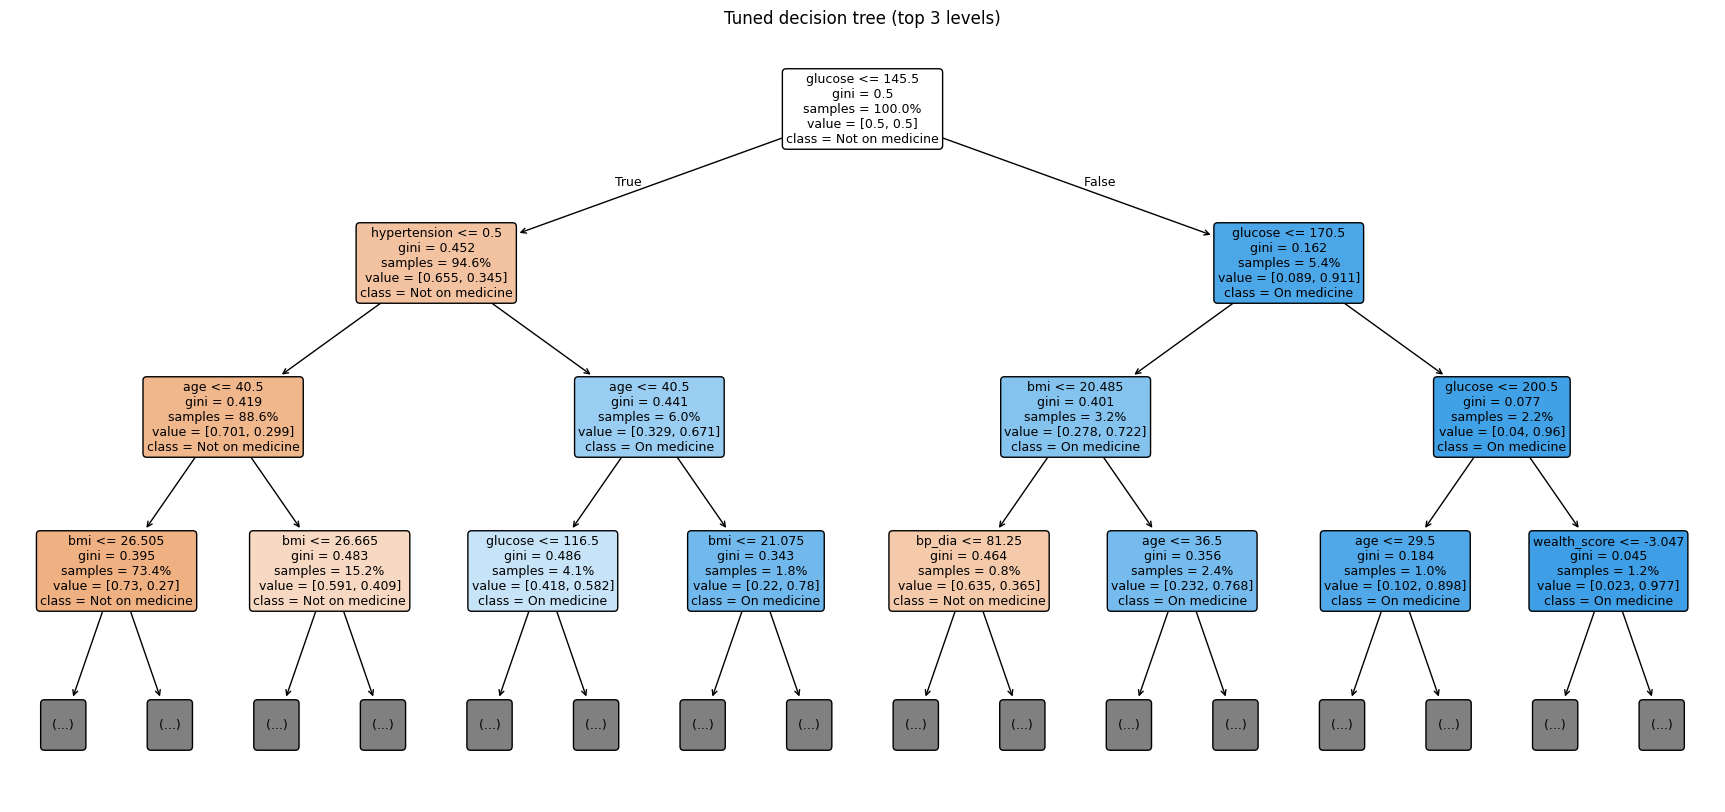

|--- glucose <= 145.50
|   |--- hypertension <= 0.50
|   |   |--- age <= 40.50
|   |   |   |--- bmi <= 26.51
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- bmi >  26.51
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- age >  40.50
|   |   |   |--- bmi <= 26.66
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- bmi >  26.66
|   |   |   |   |--- truncated branch of depth 3
|   |--- hypertension >  0.50
|   |   |--- age <= 40.50
|   |   |   |--- glucose <= 116.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- glucose >  116.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- age >  40.50
|   |   |   |--- bmi <= 21.07
|   |   |   |   |--- class: 1
|   |   |   |--- bmi >  21.07
|   |   |   |   |--- truncated branch of depth 3
|--- glucose >  145.50
|   |--- glucose <= 170.50
|   |   |--- bmi <= 20.48
|   |   |   |--- bp_dia <= 81.25
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- bp_dia >  81.25

In [8]:
# Draw the top 3 levels of the tuned tree (full tree is too large to read)
plt.figure(figsize=(22, 10))
plot_tree(tree_b, max_depth=3, feature_names=features, class_names=["Not on medicine", "On medicine"],
          filled=True, rounded=True, fontsize=9, proportion=True)
plt.title("Tuned decision tree (top 3 levels)")
plt.savefig(f"{FIG_DIR}/fig7_decision_tree.png", dpi=200, bbox_inches="tight")
plt.show()

print(export_text(tree_b, feature_names=features, max_depth=3))

In [9]:
# Highest-risk groups found by the tree: actual % on medicine in each leaf (training data)
def leaf_rules(model, X, y, feature_names, min_n=500, top_n=6):
    t = model.tree_
    parent = {}
    for node in range(t.node_count):
        for child, side in [(t.children_left[node], "<="), (t.children_right[node], ">")]:
            if child != -1:
                parent[child] = (node, side)
    leaves = pd.DataFrame({"leaf": model.apply(X), "y": y.values})
    summ = leaves.groupby("leaf")["y"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "rate"})
    summ = summ[summ["n"] >= min_n].sort_values("rate", ascending=False).head(top_n)
    rows = []
    for leaf, r in summ.iterrows():
        conds, node = [], leaf
        while node in parent:
            p, side = parent[node]
            conds.append(f"{feature_names[t.feature[p]]} {side} {t.threshold[p]:.1f}")
            node = p
        rows.append({"rule": " AND ".join(reversed(conds)), "n (train)": int(r["n"]),
                     "% on medicine": round(r["rate"] * 100, 1)})
    return pd.DataFrame(rows)

print(f"Overall rate: {y_train.mean()*100:.2f}%\n")
rules_b = leaf_rules(tree_b, X_train, y_train, features)
print(rules_b.to_string(index=False))

Overall rate: 1.19%

                                                                                                               rule  n (train)  % on medicine
 glucose > 145.5 AND glucose > 170.5 AND glucose > 200.5 AND wealth_score > -3.0 AND age > 37.5 AND glucose > 242.5       2350           46.3
glucose > 145.5 AND glucose > 170.5 AND glucose > 200.5 AND wealth_score > -3.0 AND age > 37.5 AND glucose <= 242.5       1267           34.8
                    glucose > 145.5 AND glucose > 170.5 AND glucose > 200.5 AND wealth_score > -3.0 AND age <= 37.5       1427           26.4
      glucose > 145.5 AND glucose > 170.5 AND glucose <= 200.5 AND age > 29.5 AND wealth_score > 0.1 AND age > 40.5       1500           19.9
                                   glucose > 145.5 AND glucose > 170.5 AND glucose > 200.5 AND wealth_score <= -3.0       1330           18.0
                          glucose > 145.5 AND glucose <= 170.5 AND bmi > 20.5 AND age > 36.5 AND hypertension > 0.5       1222 

              With glucose (B)  Without glucose (C)
alcohol                  0.000                0.000
female                   0.000                0.000
tobacco                  0.000                0.000
bp_sys                   0.001                0.009
edu_years                0.001                0.004
urban                    0.002                0.000
bp_dia                   0.004                0.019
wealth_score             0.014                0.109
bmi                      0.036                0.103
age                      0.043                0.549
hypertension             0.126                0.208
glucose                  0.773                0.000


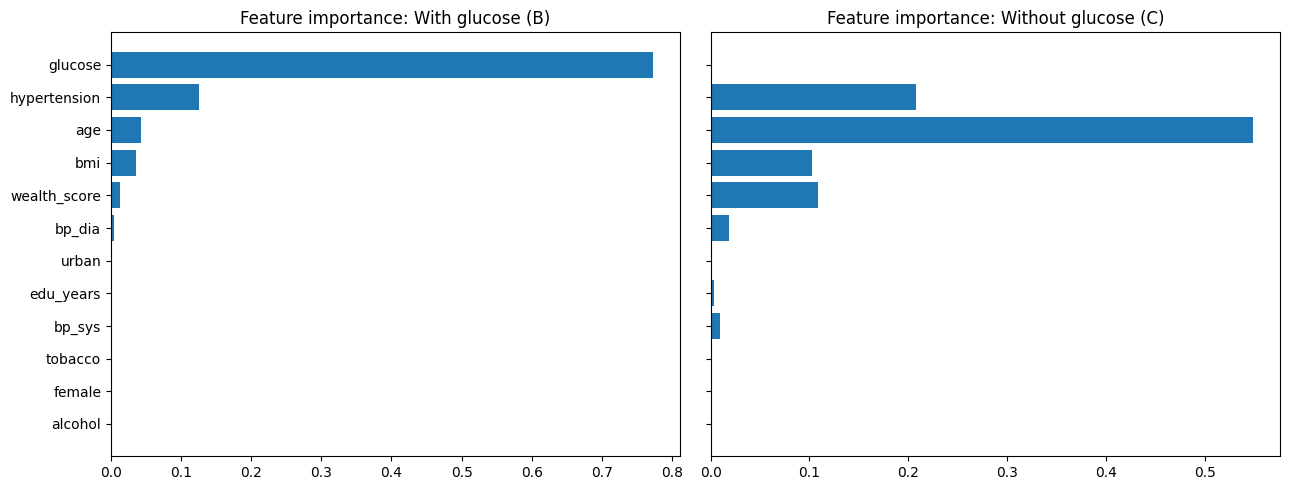

In [10]:
# Feature importance: with and without glucose
imp = pd.DataFrame({
    "With glucose (B)": pd.Series(tree_b.feature_importances_, index=features),
    "Without glucose (C)": pd.Series(tree_c.feature_importances_, index=features_nog),
}).fillna(0).sort_values("With glucose (B)")
print(imp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, col in zip(axes, imp.columns):
    ax.barh(imp.index, imp[col])
    ax.set_title(f"Feature importance: {col}")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig8_feature_importance.png", dpi=200)
plt.show()

---
# 5. Cross-validation
**5a.** Training vs testing performance (overfitting check)  
**5b.** Stability across the 5 cross-validation folds  
**5c.** ROC curves, confusion matrix and the choice of threshold  
**5d.** Validation against "currently diabetic" (self-reported diabetes and doctor-told high glucose)

In [11]:
# 5a. Training vs testing
results = pd.DataFrame([
    evaluate(tree_a, X_train, y_train, "A: unpruned, unweighted - TRAIN"),
    evaluate(tree_a, X_test,  y_test,  "A: unpruned, unweighted - TEST"),
    evaluate(tree_b, X_train, y_train, "B: tuned - TRAIN"),
    evaluate(tree_b, X_test,  y_test,  "B: tuned - TEST"),
    evaluate(tree_c, X_train[features_nog], y_train, "C: tuned, no glucose - TRAIN"),
    evaluate(tree_c, X_test[features_nog],  y_test,  "C: tuned, no glucose - TEST"),
])
print(results.round(3).to_string(index=False))
results.round(4).to_csv("model_results.csv", index=False)

                          model  accuracy  sensitivity  specificity  precision    f1   auc   TP   FN     FP     TN
A: unpruned, unweighted - TRAIN     1.000        1.000        1.000      1.000 1.000 1.000 6401    0      0 532805
 A: unpruned, unweighted - TEST     0.978        0.171        0.988      0.143 0.156 0.579  468 2275   2799 225547
               B: tuned - TRAIN     0.875        0.657        0.878      0.061 0.111 0.816 4208 2193  65115 467690
                B: tuned - TEST     0.874        0.636        0.877      0.058 0.107 0.797 1745  998  28086 200260
   C: tuned, no glucose - TRAIN     0.781        0.634        0.783      0.034 0.064 0.767 4059 2342 115618 417187
    C: tuned, no glucose - TEST     0.780        0.606        0.782      0.032 0.061 0.746 1662 1081  49739 178607


In [12]:
# 5b. Fold-by-fold AUC for the chosen settings
b = grid.best_index_
folds = [cv_res.loc[b, f"split{k}_test_score"] for k in range(5)]
print("Validation AUC by fold:", np.round(folds, 4))
print(f"Mean {np.mean(folds):.4f}  |  SD {np.std(folds):.4f}  |  Test-set AUC {roc_auc_score(y_test, tree_b.predict_proba(X_test)[:,1]):.4f}")

Validation AUC by fold: [0.8006 0.7959 0.8129 0.8173 0.8057]
Mean 0.8065  |  SD 0.0078  |  Test-set AUC 0.7967


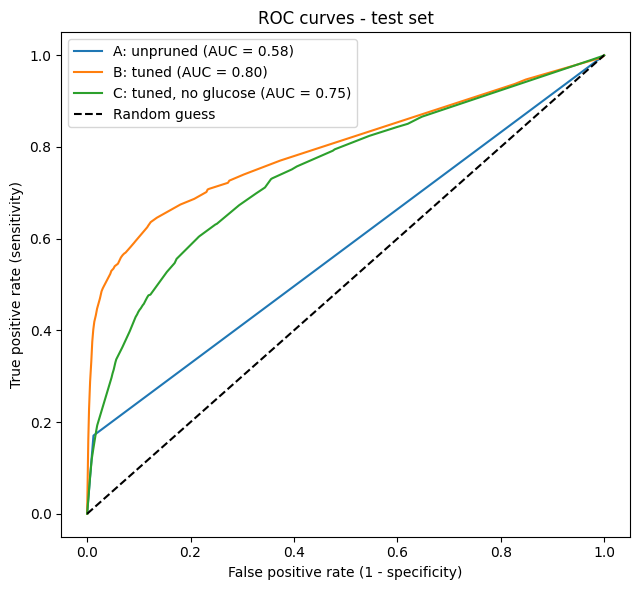

In [13]:
# 5c. ROC curves on the TEST set
plt.figure(figsize=(6.5, 6))
for model, Xt, name in [(tree_a, X_test, "A: unpruned"), (tree_b, X_test, "B: tuned"),
                        (tree_c, X_test[features_nog], "C: tuned, no glucose")]:
    p = model.predict_proba(Xt)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate (1 - specificity)")
plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC curves - test set")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig9_roc_curves.png", dpi=200)
plt.show()

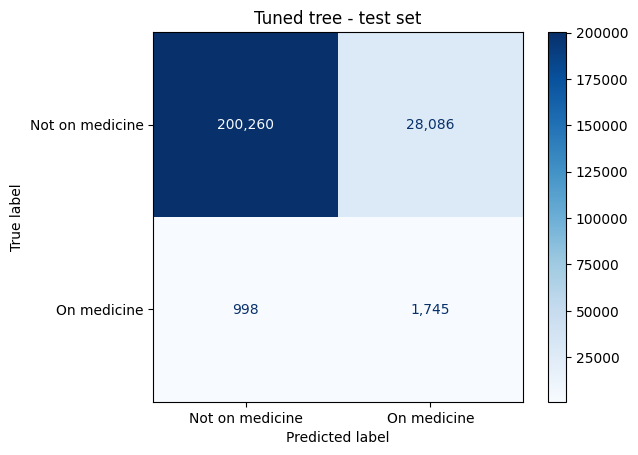

                 precision    recall  f1-score   support

Not on medicine       1.00      0.88      0.93    228346
    On medicine       0.06      0.64      0.11      2743

       accuracy                           0.87    231089
      macro avg       0.53      0.76      0.52    231089
   weighted avg       0.98      0.87      0.92    231089



In [14]:
# Confusion matrix of the tuned model on the test set
cm = confusion_matrix(y_test, tree_b.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=["Not on medicine", "On medicine"]).plot(cmap="Blues", values_format=",")
plt.title("Tuned tree - test set")
plt.savefig(f"{FIG_DIR}/fig10_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()
print(classification_report(y_test, tree_b.predict(X_test), target_names=["Not on medicine", "On medicine"]))

In [15]:
# Threshold choice: trade-off between catching diabetics and false alarms
p_b = tree_b.predict_proba(X_test)[:, 1]
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    r = evaluate(tree_b, X_test, y_test, f"threshold {t}", threshold=t)
    r["% of people flagged"] = (p_b >= t).mean() * 100
    rows.append(r)
thr = pd.DataFrame(rows)[["model", "sensitivity", "specificity", "precision", "% of people flagged"]]
print(thr.round(3).to_string(index=False))

        model  sensitivity  specificity  precision  % of people flagged
threshold 0.3        0.727        0.725      0.031               28.041
threshold 0.4        0.674        0.820      0.043               18.621
threshold 0.5        0.636        0.877      0.058               12.909
threshold 0.6        0.564        0.931      0.090                7.445
threshold 0.7        0.523        0.955      0.123                5.041
threshold 0.8        0.491        0.970      0.164                3.564
threshold 0.9        0.419        0.986      0.266                1.870


In [16]:
# 5d. Validation against other measures of 'currently diabetic' (test set)
test = df.loc[X_test.index].copy()
test["p_b"] = p_b
test["p_c"] = tree_c.predict_proba(X_test[features_nog])[:, 1]
test["flag_b"] = (test["p_b"] >= 0.5).astype(int)
test["flag_c"] = (test["p_c"] >= 0.5).astype(int)

val = []
for outcome, label in [("diab_med", "On diabetes medicine (training target)"),
                       ("diab_self", "Self-reports 'currently has diabetes'"),
                       ("diab_told", "Told high blood glucose by a health professional")]:
    s = test.dropna(subset=[outcome])
    val.append({"outcome": label, "n": len(s), "% positive": round(s[outcome].mean() * 100, 2),
                "AUC model B": round(roc_auc_score(s[outcome], s["p_b"]), 3),
                "AUC model C (no glucose)": round(roc_auc_score(s[outcome], s["p_c"]), 3)})
print(pd.DataFrame(val).to_string(index=False))

# People with high glucose (>140 mg/dL) who are NOT on medicine: undiagnosed or untreated
hidden = test[(test["glucose"] > 140) & (test["diab_med"] == 0)]
print(f"\nTest-set people with glucose >140 but not on medicine: {len(hidden):,} "
      f"({len(hidden)/len(test)*100:.2f}% of test set; vs {test['diab_med'].sum():,} on medicine)")
print(f"  flagged by model B (with glucose):    {hidden['flag_b'].mean()*100:.1f}%")
print(f"  flagged by model C (without glucose): {hidden['flag_c'].mean()*100:.1f}%")

                                         outcome      n  % positive  AUC model B  AUC model C (no glucose)
          On diabetes medicine (training target) 231089        1.19        0.797                     0.746
           Self-reports 'currently has diabetes' 228429        1.66        0.770                     0.740
Told high blood glucose by a health professional 231089        1.86        0.834                     0.788

Test-set people with glucose >140 but not on medicine: 14,464 (6.26% of test set; vs 2,743.0 on medicine)
  flagged by model B (with glucose):    69.2%
  flagged by model C (without glucose): 42.8%


---
# 6. Hypothesis tests for inferences
Each hypothesis is checked by comparing the % on diabetes medicine across groups and with a
**chi-square test** (is the factor independent of diabetes?). With ~770,000 people even tiny differences
are "statistically significant", so the size of the difference matters more than the p-value.

Note: NFHS-5 does not record family history of diabetes, so genetic risk cannot be tested directly.

In [17]:
# Chi-square test + % on medicine in each group
rows = []
for v in ["age_group", "female", "urban", "wealth_quintile", "edu_level", "bmi_cat",
          "hypertension", "alcohol", "tobacco"]:
    tab = pd.crosstab(df[v], df[target])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    rates = (df.groupby(v, observed=True)[target].mean() * 100).round(2)
    rows.append({"variable": v, "chi2": round(chi2, 1), "df": dof, "p-value": p,
                 "lowest %": rates.min(), "highest %": rates.max(),
                 "highest / lowest": round(rates.max() / rates.min(), 1)})
    print(f"\n{v}: % on medicine by group"); print(rates.to_string())
print("\n")
print(pd.DataFrame(rows).sort_values("chi2", ascending=False).to_string(index=False))


age_group: % on medicine by group
age_group
15-19    0.47
20-24    0.49
25-29    0.58
30-34    0.81
35-39    1.32
40-44    2.20
45-49    3.40

female: % on medicine by group
female
0    1.31
1    1.17

urban: % on medicine by group
urban
0    0.98
1    1.82

wealth_quintile: % on medicine by group
wealth_quintile
1    0.61
2    0.83
3    1.16
4    1.61
5    1.94

edu_level: % on medicine by group
edu_level
0    1.21
1    1.33
2    1.17
3    1.09

bmi_cat: % on medicine by group
bmi_cat
Normal (18.5-24.9)      0.87
Obese (30+)             3.96
Overweight (25-29.9)    2.16
Underweight (<18.5)     0.55

hypertension: % on medicine by group
hypertension
0.0    0.9
1.0    5.1

alcohol: % on medicine by group
alcohol
0    1.18
1    1.28

tobacco: % on medicine by group
tobacco
0    1.19
1    1.14


       variable   chi2  df       p-value  lowest %  highest %  highest / lowest
   hypertension 7254.3   1  0.000000e+00      0.90       5.10               5.7
      age_group 6110.6   6  0.00000

In [18]:
print("Saved: model_results.csv and figures fig7-fig10 in", FIG_DIR)

Saved: model_results.csv and figures fig7-fig10 in figures
